# Triplet counts from m of k partitions

A triplet can lie in one, two or three distinct partitions, and each case
survives the selection of m partitions with a different probability. The
N-point estimators count the three classes separately and weight each by the
inverse of its probability. They need m ≥ N.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from pysauce import (
    compute_npcf,
    compute_npcf3_shape,
    compute_npcf3_smu,
    count_npoint,
    partition_weights,
)

np.set_printoptions(precision=1, suppress=True)

## A mock catalogue

The mock of `01_xi_r.ipynb`: galaxies in randomly placed haloes, each halo in
one of k = 8 partitions.

In [2]:
def clustered_mock(n_haloes, mean_members, halo_size, box_size, k, rng):
    """Galaxies scattered around randomly placed haloes.

    Every galaxy of a halo gets that halo's partition label, as when each
    partition holds the galaxies of one file of merger trees.
    """
    centres = rng.uniform(0, box_size, (n_haloes, 3))
    halo = np.repeat(np.arange(n_haloes), rng.poisson(mean_members, n_haloes))
    coords = (centres[halo] + rng.normal(0, halo_size, (len(halo), 3))) % box_size
    coords[coords >= box_size] = 0.0  # the modulo can round up to box_size
    partition_ids = rng.integers(0, k, n_haloes, dtype=np.int32)[halo]
    return coords, partition_ids


BOX_SIZE = 500.0  # Mpc/h
K = 8             # partitions in the full catalogue

rng = np.random.default_rng(1)
coords, partition_ids = clustered_mock(40_000, 5, 1.0, BOX_SIZE, K, rng)
print(f"{len(coords):,} galaxies in {K} partitions")

199,659 galaxies in 8 partitions


In [3]:
def select(chosen):
    """The galaxies of the chosen partitions."""
    keep = np.isin(partition_ids, chosen)
    return coords[keep], partition_ids[keep]

## Counts and weights

A triplet is counted when all three of its sides are shorter than
`r_bins[-1]`, and is binned by its longest side. `count_npoint` returns the
raw counts split by the number of partitions s the triplet spans. (The
`count_*` functions do not convert their arguments: positions must be float64
and partition labels int32.)

In [4]:
r_bins = np.array([0.5, 1.0, 2.0, 4.0, 8.0])
M = 3

counts_by_s, total = count_npoint(*select([0, 1, 2]), r_bins, BOX_SIZE, n_order=3)
weights = partition_weights(K, M, n_order=3, scale_method="scale-up")
for s in range(3):
    print(f"s = {s + 1}: weight {weights[s]:5.1f}, counts {counts_by_s[s]}")

s = 1: weight   2.7, counts [  1466.  45490. 234219.  96058.]
s = 2: weight   9.3, counts [    15.    624.  12145. 123060.]
s = 3: weight  56.0, counts [   0.    0.   33. 2013.]


`compute_npcf` does both steps. `t_total` is the raw count of the selected
galaxies and `t_corr` the estimate for the full catalogue.

In [5]:
full = compute_npcf(
    coords, partition_ids, r_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=K, n_order=3,
)
sparse = compute_npcf(
    *select([0, 1, 2]), r_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=M, n_order=3,
)
print("full box:        ", full["t_total"])
print("3 of 8, raw:     ", sparse["t_total"])
print("3 of 8, corrected:", sparse["t_corr"])

full box:         [   4007.  125590.  730799. 1523446.]
3 of 8, raw:      [  1481.  46114. 246397. 221131.]
3 of 8, corrected: [   4049.3  127130.7  739785.3 1517442.7]


## Every selection

Averaged over all 56 ways of choosing 3 partitions from 8, the corrected
counts are the counts of the full box.

largest relative difference: 2.220446049250313e-16


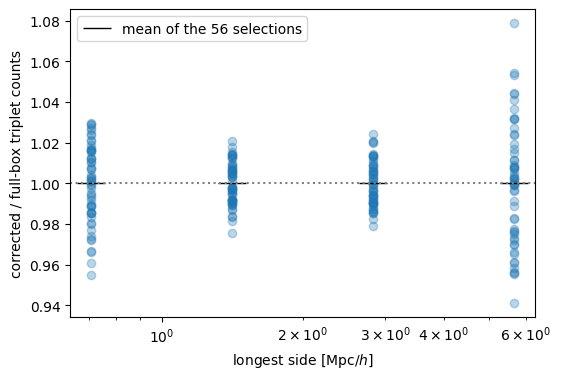

In [6]:
selections = list(combinations(range(K), M))
corrected = np.array([
    compute_npcf(
        *select(chosen), r_bins, BOX_SIZE,
        n_partitions=K, n_partitions_selected=M, n_order=3,
    )["t_corr"]
    for chosen in selections
])
print("largest relative difference:", np.max(np.abs(corrected.mean(axis=0) / full["t_total"] - 1)))

r = np.sqrt(r_bins[:-1] * r_bins[1:])
fig, ax = plt.subplots(figsize=(6, 4))
for t_corr in corrected:
    ax.semilogx(r, t_corr / full["t_total"], "o", color="C0", alpha=0.3)
ax.semilogx(r, corrected.mean(axis=0) / full["t_total"], "k_", ms=20, label="mean of the 56 selections")
ax.axhline(1, color="grey", ls=":")
ax.set_xlabel(r"longest side [Mpc/$h$]")
ax.set_ylabel("corrected / full-box triplet counts")
ax.legend()
plt.show()

## Shape and orientation

`compute_npcf3_shape` also bins each triplet by the ratio of its shortest to
its longest side, and `compute_npcf3_smu` by the angle between its longest
side and the line of sight. Both return arrays of shape (n_r, n_bins) whose
sum over the second axis is the count above.

In [7]:
by_shape = compute_npcf3_shape(
    *select([0, 1, 2]), r_bins, 5, BOX_SIZE, n_partitions=K, n_partitions_selected=M
)
by_mu = compute_npcf3_smu(
    *select([0, 1, 2]), r_bins, 5, BOX_SIZE, n_partitions=K, n_partitions_selected=M
)
print(by_shape["t_corr"].shape, by_mu["t_corr"].shape)
print(np.allclose(by_shape["t_corr"].sum(axis=1), sparse["t_corr"]))
print(np.allclose(by_mu["t_corr"].sum(axis=1), sparse["t_corr"]))

(4, 5) (4, 5)
True
True


## Higher orders

`n_order` can be up to 8. The cost grows quickly with the order and with
`r_bins[-1]`, so start with a small radius. For large calculations
`count_npoint` can count one of `n_shards` shares of the work at a time
(`shard_idx`), to be summed afterwards.

In [8]:
small_bins = np.array([0.5, 1.0, 2.0])
four = compute_npcf(
    *select([0, 1, 2, 3]), small_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=4, n_order=4,
)
print("weights:", four["weights"])
print("corrected 4-tuple counts:", four["t_corr"])

weights: [ 2.   4.7 14.  70. ]
corrected 4-tuple counts: [  231.3 51295.3]
